<a href="https://colab.research.google.com/github/Avinash2567/MACHINE-LEARNING-ALGORITHM-IMPLEMENTATIONS/blob/main/03-cross-validation/03-cross-validation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset Shape: (1000, 9)
Columns: ['Order_ID', 'Distance_km', 'Weather', 'Traffic_Level', 'Time_of_Day', 'Vehicle_Type', 'Preparation_Time_min', 'Courier_Experience_yrs', 'Delivery_Time_min']


,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
0,522,7.93,Windy,Low,Afternoon,Scooter,12,1.0,43
1,738,16.42,Clear,Medium,Evening,Bike,20,2.0,84
2,741,9.52,Foggy,Low,Night,Scooter,28,1.0,59
3,661,7.44,Rainy,Medium,Afternoon,Scooter,5,1.0,37
4,412,19.03,Clear,Low,Morning,Bike,16,5.0,68



Linear Regression
MAE per fold: [6.063 7.52  6.298 7.162 5.959]
MSE per fold: [ 80.141 148.788  88.417 157.583  90.67 ]
RMSE per fold: [ 8.952 12.198  9.403 12.553  9.522]
R2 per fold: [0.821 0.721 0.807 0.706 0.799]

Random Forest
MAE per fold: [6.805 8.296 7.597 8.083 6.931]
MSE per fold: [ 92.212 166.608 114.919 180.488 121.946]
RMSE per fold: [ 9.603 12.908 10.72  13.435 11.043]
R2 per fold: [0.794 0.687 0.75  0.664 0.73 ]

Cross-Validation Results


,Model,Mean MAE,Mean MSE,Mean RMSE,Mean R2
0,Linear Regression,6.6006,113.1197,10.5257,0.771
1,Random Forest,7.5424,135.2347,11.5416,0.725


Best Model based on Mean RMSE: Linear Regression


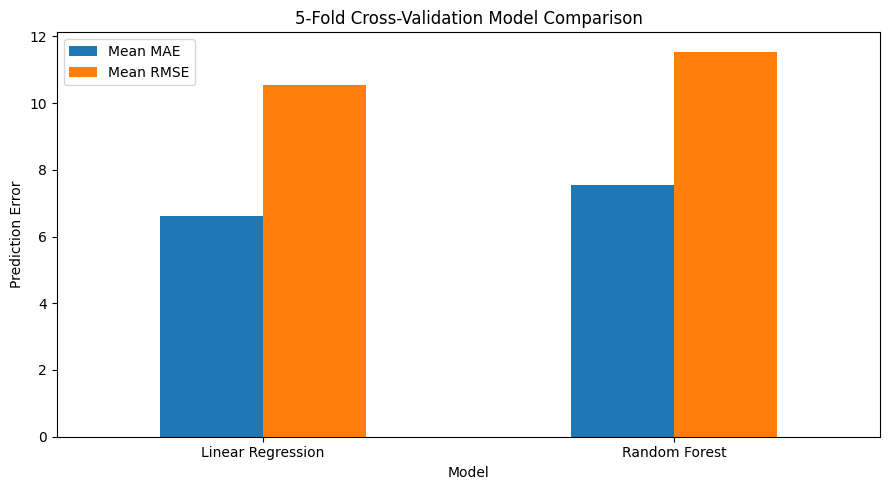

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.model_selection import KFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

# Direct path to the selected file
csv_file = "/content/Food_Delivery_Times.csv"

df = pd.read_csv(csv_file)
df.columns = df.columns.str.strip()

print("Dataset Shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

target_candidates = [
    "Delivery_Time_min",
    "Delivery_Time",
    "Time_taken(min)",
    "delivery_time",
    "delivery_time_min"
]

target = next(
    (col for col in target_candidates if col in df.columns),
    None
)

if target is None:
    raise ValueError(
        "Target column not found. Available columns: "
        + str(df.columns.tolist())
    )

df = df.drop_duplicates()
y = pd.to_numeric(df[target], errors="coerce")
valid = y.notna()

df = df.loc[valid].reset_index(drop=True)
y = y.loc[valid].reset_index(drop=True)

X = df.drop(columns=[target])

X = X.drop(
    columns=[
        col for col in X.columns
        if col.lower() in ["order_id", "id"]
    ],
    errors="ignore"
)

numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=["number"]
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "mae": "neg_mean_absolute_error",
    "mse": "neg_mean_squared_error",
    "r2": "r2"
}

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=1
    )
}

results = []

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    scores = cross_validate(
        pipeline,
        X,
        y,
        cv=kfold,
        scoring=scoring,
        n_jobs=-1
    )

    fold_mae = -scores["test_mae"]
    fold_mse = -scores["test_mse"]
    fold_rmse = np.sqrt(fold_mse)
    fold_r2 = scores["test_r2"]

    results.append({
        "Model": name,
        "Mean MAE": fold_mae.mean(),
        "Mean MSE": fold_mse.mean(),
        "Mean RMSE": fold_rmse.mean(),
        "Mean R2": fold_r2.mean()
    })

    print(f"\n{name}")
    print("MAE per fold:", np.round(fold_mae, 3))
    print("MSE per fold:", np.round(fold_mse, 3))
    print("RMSE per fold:", np.round(fold_rmse, 3))
    print("R2 per fold:", np.round(fold_r2, 3))

comparison = pd.DataFrame(results)

print("\nCross-Validation Results")
display(comparison.round(4))

best_model = comparison.loc[
    comparison["Mean RMSE"].idxmin(), "Model"
]

print("Best Model based on Mean RMSE:", best_model)

comparison.set_index("Model")[
    ["Mean MAE", "Mean RMSE"]
].plot(kind="bar", figsize=(9, 5))

plt.title("5-Fold Cross-Validation Model Comparison")
plt.ylabel("Prediction Error")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()